<a href="https://colab.research.google.com/github/Arjx01/ML2_Arjun-M_4NI23CI019/blob/main/ML2_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First five rows:


,Customer_ID,Annual_Income_k,Spending_Score
0,1,-1.283177,9.127762
1,2,1.135148,4.847704
2,3,-2.373436,7.740501
3,4,4.461109,2.544370
4,5,-3.372519,9.142246



Dataset shape: (300, 3)

Missing values:
 Customer_ID        0
Annual_Income_k    0
Spending_Score     0
dtype: int64


,K (number of clusters),WCSS / Inertia
0,1,600.000000
1,2,302.763080
2,3,68.444632
3,4,21.022833
4,5,9.859522
5,6,8.615515
6,7,7.790400
7,8,7.210449
8,9,6.701616
9,10,6.061897


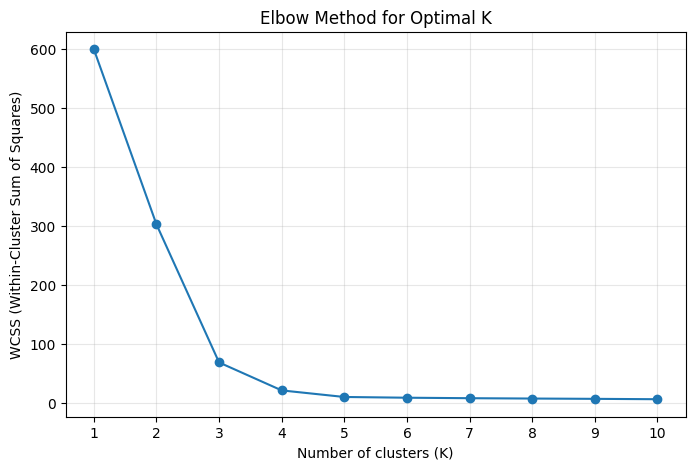

,K,Silhouette Score
0,2,0.595630
1,3,0.739196
2,4,0.791511
3,5,0.762042
4,6,0.678973
5,7,0.622900
6,8,0.499217
7,9,0.568249
8,10,0.406105


Cluster centers (original feature units):


,Annual_Income_k,Spending_Score
Cluster,,
0,2.009785,4.100308
1,-6.744275,-6.942637
2,-8.844513,7.306211
3,-2.598047,8.964418
4,4.558382,2.129614


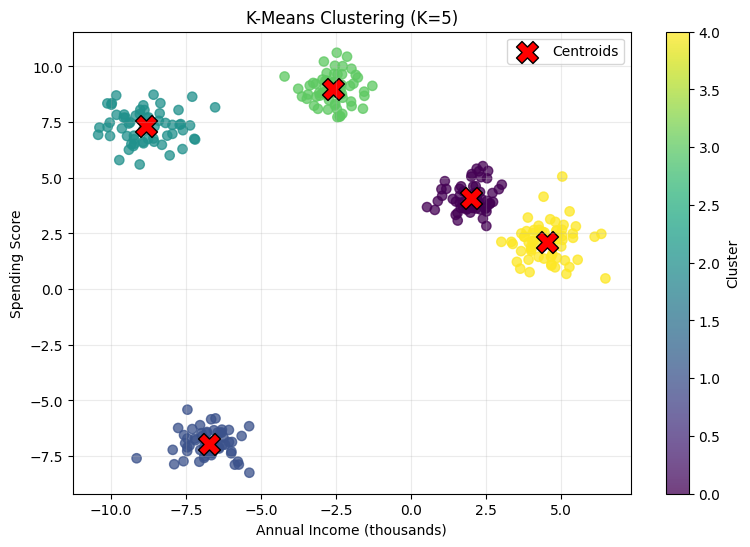

Cluster counts:


,Number of customers
Cluster,
0,60
1,60
2,60
3,60
4,60


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from google.colab import files
import os

if os.path.exists("/content/kmeans_customer_data.csv"):
    df = pd.read_csv("/content/kmeans_customer_data.csv")
else:
    print("Upload kmeans_customer_data.csv")
    uploaded = files.upload()
    filename = next(iter(uploaded))
    df = pd.read_csv(filename)

print("First five rows:")
display(df.head())
print("\nDataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

features = ["Annual_Income_k", "Spending_Score"]
X = df[features].copy()

X = X.fillna(X.median(numeric_only=True))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k_values = range(1, 11)
wcss = []

for k in k_values:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

elbow_results = pd.DataFrame({"K (number of clusters)": list(k_values), "WCSS / Inertia": wcss})
display(elbow_results)

plt.figure(figsize=(8, 5))
plt.plot(k_values, wcss, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

optimal_k = 5

silhouette_results = []
for k in range(2, 11):
    candidate = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = candidate.fit_predict(X_scaled)
    silhouette_results.append({"K": k, "Silhouette Score": silhouette_score(X_scaled, labels)})

display(pd.DataFrame(silhouette_results))

kmeans = KMeans(n_clusters=optimal_k, init="k-means++", n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers_original, columns=features)
centers_df.index.name = "Cluster"
print("Cluster centers (original feature units):")
display(centers_df)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["Annual_Income_k"], df["Spending_Score"],
    c=df["Cluster"], cmap="viridis", s=45, alpha=0.75
)
plt.scatter(
    centers_original[:, 0], centers_original[:, 1],
    marker="X", s=250, c="red", edgecolor="black", label="Centroids"
)
plt.title(f"K-Means Clustering (K={optimal_k})")
plt.xlabel("Annual Income (thousands)")
plt.ylabel("Spending Score")
plt.legend()
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.25)
plt.show()

print("Cluster counts:")
display(df["Cluster"].value_counts().sort_index().rename("Number of customers").to_frame())

output_path = "/content/kmeans_clustered_results.csv"
df.to_csv(output_path, index=False)
